In [1]:
%pip install medmnist tensorflow scikit-learn matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


CNN-BASED CHEST X-RAY CLASSIFICATION
TensorFlow Version: 2.21.0

Loading PneumoniaMNIST Dataset...


100%|██████████| 4.17M/4.17M [00:12<00:00, 322kB/s]



Training Data Shape: (4708, 28, 28, 1)
Validation Data Shape: (524, 28, 28, 1)
Testing Data Shape: (624, 28, 28, 1)

Training Class Distribution:
Normal : 1214
Pneumonia : 3494


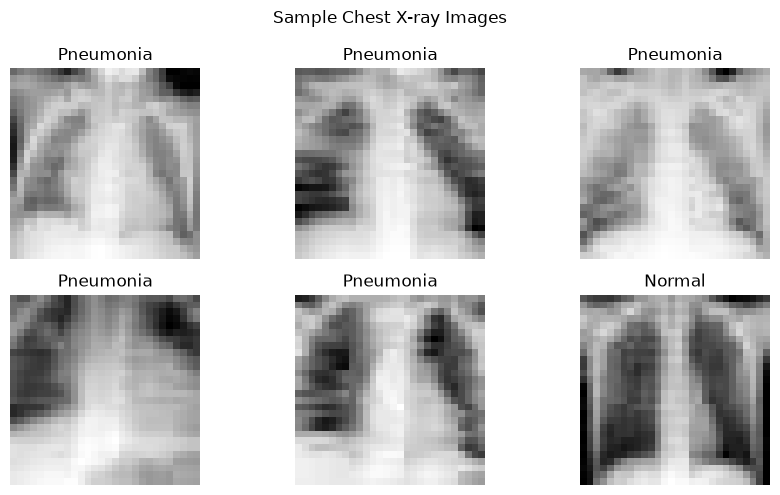


CNN Model Summary:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       401,536 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 420,481 (1.60 MB)

 Trainable params: 420,481 (1.60 MB)

 Non-trainable params: 0 (0.00 B)


Training CNN Model...
Epoch 1/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 6s 32ms/step - accuracy: 0.7770 - loss: 0.4343 - val_accuracy: 0.9008 - val_loss: 0.2540
Epoch 2/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.9046 - loss: 0.2344 - val_accuracy: 0.9275 - val_loss: 0.2013
Epoch 3/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9286 - loss: 0.1912 - val_accuracy: 0.9637 - val_loss: 0.1424
Epoch 4/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9382 - loss: 0.1667 - val_accuracy: 0.9580 - val_loss: 0.1329
Epoch 5/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9473 - loss: 0.1464 - val_accuracy: 0.9561 - val_loss: 0.1327
Epoch 6/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 26ms/step - accuracy: 0.9475 - loss: 0.1419 - val_accuracy: 0.9599 - val_loss: 0.1189
Epoch 7/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 24ms/step - accuracy: 0.9518 - loss: 0.1295 - val_accuracy: 0.9485 - val_loss: 0.1348
Epoch 8/15
74/74 ━━━━━━━━━━━━━━━━━━━━ 2s 27ms/step - accuracy: 0.9548 - loss: 0.1255 - v

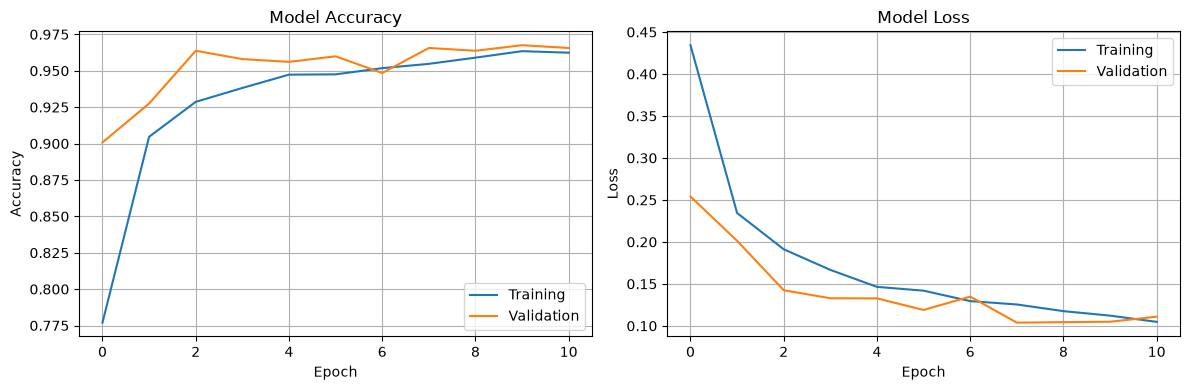


Classification Report:
              precision    recall  f1-score   support

      Normal       0.98      0.55      0.70       234
   Pneumonia       0.78      0.99      0.88       390

    accuracy                           0.83       624
   macro avg       0.88      0.77      0.79       624
weighted avg       0.86      0.83      0.81       624



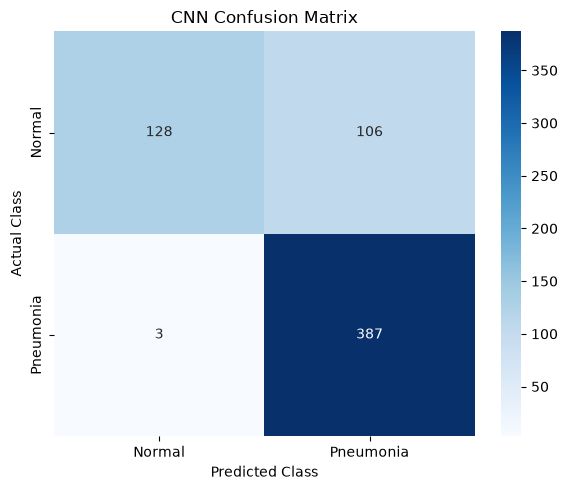


Sample Prediction
Actual Class: Pneumonia
Predicted Class: Pneumonia
Model Score: 100.0 %


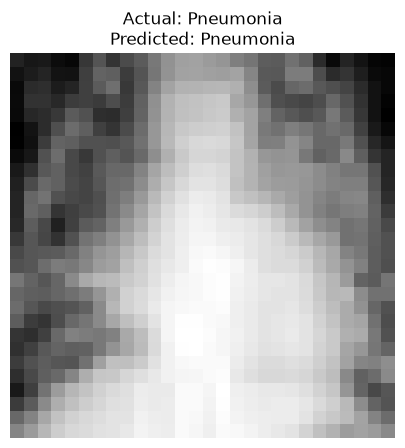


EXPERIMENT COMPLETED SUCCESSFULLY
Total Training Images: 4708
Total Testing Images: 624
Number of Classes: 2
Test Accuracy: 82.53 %


In [2]:

# Experiment: Medical Image Classification using CNN

# 1. Import Libraries
import os

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from medmnist import PneumoniaMNIST

from tensorflow.keras import Sequential
from tensorflow.keras.layers import (
    Input,
    Conv2D,
    MaxPooling2D,
    Flatten,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)


# 2. Set Configuration
MODEL_PATH = "pneumonia_cnn.keras"

CLASS_NAMES = ["Normal", "Pneumonia"]

print("=" * 55)
print("CNN-BASED CHEST X-RAY CLASSIFICATION")
print("=" * 55)

print("TensorFlow Version:", tf.__version__)


# 3. Load PneumoniaMNIST Dataset
print("\nLoading PneumoniaMNIST Dataset...")

train_data = PneumoniaMNIST(split="train", download=True)
val_data = PneumoniaMNIST(split="val", download=True)
test_data = PneumoniaMNIST(split="test", download=True)


# 4. Preprocess Dataset
def prepare_data(dataset):

    # Normalize image pixel values
    images = dataset.imgs.astype(np.float32) / 255.0

    # Convert labels into one-dimensional array
    labels = dataset.labels.flatten().astype(np.float32)

    # Add channel dimension for grayscale images
    images = images[..., np.newaxis]

    return images, labels


X_train, y_train = prepare_data(train_data)
X_val, y_val = prepare_data(val_data)
X_test, y_test = prepare_data(test_data)


print("\nTraining Data Shape:", X_train.shape)
print("Validation Data Shape:", X_val.shape)
print("Testing Data Shape:", X_test.shape)


# 5. Display Class Distribution
print("\nTraining Class Distribution:")

classes, counts = np.unique(y_train, return_counts=True)

for class_id, count in zip(classes, counts):
    print(CLASS_NAMES[int(class_id)], ":", count)


# 6. Display Sample Images
plt.figure(figsize=(9, 5))

for i in range(6):

    plt.subplot(2, 3, i + 1)

    plt.imshow(X_train[i].squeeze(), cmap="gray")

    plt.title(CLASS_NAMES[int(y_train[i])])

    plt.axis("off")

plt.suptitle("Sample Chest X-ray Images")
plt.tight_layout()
plt.show()


# 7. Build CNN Model
def build_cnn():

    cnn = Sequential([

        Input(shape=(28, 28, 1)),

        Conv2D(32, 3, activation="relu", padding="same"),

        MaxPooling2D(pool_size=2),

        Conv2D(64, 3, activation="relu", padding="same"),

        MaxPooling2D(pool_size=2),

        Flatten(),

        Dense(128, activation="relu"),

        Dropout(0.4),

        Dense(1, activation="sigmoid")

    ])

    cnn.compile(

        optimizer=Adam(learning_rate=0.001),

        loss="binary_crossentropy",

        metrics=["accuracy"]

    )

    return cnn


# 8. Train or Load CNN Model
if os.path.exists(MODEL_PATH):

    model = tf.keras.models.load_model(MODEL_PATH)

    history = None

    print("\nSaved CNN Model Loaded Successfully.")

else:

    model = build_cnn()

    print("\nCNN Model Summary:")
    model.summary()

    early_stop = EarlyStopping(

        monitor="val_loss",

        patience=3,

        restore_best_weights=True

    )

    print("\nTraining CNN Model...")

    history = model.fit(

        X_train,
        y_train,

        validation_data=(X_val, y_val),

        epochs=15,

        batch_size=64,

        callbacks=[early_stop],

        verbose=1

    )

    model.save(MODEL_PATH)

    print("\nModel Saved Successfully:", MODEL_PATH)


# 9. Evaluate Model
test_loss, test_accuracy = model.evaluate(

    X_test,
    y_test,

    verbose=0

)

print("\nTest Loss:", round(test_loss, 4))

print("Test Accuracy:", round(test_accuracy * 100, 2), "%")


# 10. Plot Training and Validation Curves
if history is not None:

    fig, axes = plt.subplots(1, 2, figsize=(12, 4))

    # Accuracy Graph
    axes[0].plot(
        history.history["accuracy"],
        label="Training"
    )

    axes[0].plot(
        history.history["val_accuracy"],
        label="Validation"
    )

    axes[0].set_title("Model Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True)

    # Loss Graph
    axes[1].plot(
        history.history["loss"],
        label="Training"
    )

    axes[1].plot(
        history.history["val_loss"],
        label="Validation"
    )

    axes[1].set_title("Model Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True)

    plt.tight_layout()
    plt.show()


# 11. Predict Test Dataset
probabilities = model.predict(
    X_test,
    verbose=0
).flatten()

y_pred = (probabilities >= 0.5).astype(int)


# 12. Classification Report
print("\nClassification Report:")

print(

    classification_report(

        y_test.astype(int),

        y_pred,

        target_names=CLASS_NAMES,

        zero_division=0

    )

)


# 13. Plot Confusion Matrix
cm = confusion_matrix(

    y_test.astype(int),

    y_pred

)

plt.figure(figsize=(6, 5))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Blues",

    xticklabels=CLASS_NAMES,

    yticklabels=CLASS_NAMES

)

plt.title("CNN Confusion Matrix")

plt.xlabel("Predicted Class")

plt.ylabel("Actual Class")

plt.tight_layout()
plt.show()


# 14. Display Sample Prediction
sample_index = min(10, len(X_test) - 1)

actual = int(y_test[sample_index])

predicted = int(y_pred[sample_index])

confidence = probabilities[sample_index]

print("\nSample Prediction")

print("Actual Class:", CLASS_NAMES[actual])

print("Predicted Class:", CLASS_NAMES[predicted])

score = confidence if predicted == 1 else 1 - confidence

print("Model Score:", round(score * 100, 2), "%")


plt.figure(figsize=(5, 5))

plt.imshow(
    X_test[sample_index].squeeze(),
    cmap="gray"
)

plt.title(

    f"Actual: {CLASS_NAMES[actual]}\n"
    f"Predicted: {CLASS_NAMES[predicted]}"

)

plt.axis("off")
plt.show()


# 15. Final Results
final_accuracy = accuracy_score(

    y_test.astype(int),

    y_pred

)

print("\n" + "=" * 55)

print("EXPERIMENT COMPLETED SUCCESSFULLY")

print("=" * 55)

print("Total Training Images:", len(X_train))

print("Total Testing Images:", len(X_test))

print("Number of Classes:", len(CLASS_NAMES))

print("Test Accuracy:", round(final_accuracy * 100, 2), "%")
